# RQ2 — LLM–human agreement by criterion and the effect of representation

**Question:** Which evaluation criteria show stronger LLM–human agreement, and does input representation (image vs text) alter agreement within each criterion?

**Design:**
- Same join and labels as RQ1, but metrics are computed per `(Representation, Criterion)`.
- Precision, recall and F1 per cell, each with a **bootstrap** 95% CI (per-criterion samples are smaller, so CIs are wider).
- Image-vs-text difference per criterion via bootstrap CI.
- Charts: empirical boxplots (per-diagram values); ordinal kappa by criterion in RQ2.

> Like RQ1, if `ground_truth_binary.csv` is missing the notebook runs in a flagged **DRY-RUN** mode (boundary mean=2.5 -> 1) and does not save outputs."

## 1. Setup, load and join (same pipeline as RQ1)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import analysis_utils as au

NOTEBOOK_DIR = Path.cwd()
CSV_DIR = NOTEBOOK_DIR.parent
FIG_DIR = NOTEBOOK_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

EVAL_BINARY = CSV_DIR / "llm-evaluations" / "evaluations_binary.csv"
GT_BINARY = CSV_DIR / "ground-truth" / "ground_truth_binary.csv"
GT_ORDINAL = CSV_DIR / "ground-truth" / "ground_truth_ordinal.csv"
OUT_TABLE = NOTEBOOK_DIR / "rq2_per_criterion.csv"
OUT_TABLE_AGGREGATED = NOTEBOOK_DIR / "rq2_f1_per_criterion_aggregated.csv"

DRY_RUN = False
if GT_BINARY.exists():
    gt = pd.read_csv(GT_BINARY)
    print(f"OK - real binarized ground truth loaded ({len(gt)} rows)")
else:
    DRY_RUN = True
    print("DRY-RUN MODE: ground_truth_binary.csv not found; using ordinal means (2.5 -> 1).")
    print("Outputs will NOT be saved. Fill BOUNDARY_DECISIONS and re-run for real results.")
    gt_ord = pd.read_csv(GT_ORDINAL)
    gt = gt_ord[["Diagram_ID", "Criterion", "Guideline"]].copy()
    gt["gt_label"] = (gt_ord["gt_score_mean"] >= 2.5).astype(int)

gt = gt[["Diagram_ID", "Criterion", "Guideline", "gt_label"]]

evals = pd.read_csv(EVAL_BINARY)
evals["Representation"] = evals["Format"].apply(au.format_to_representation)
merged = evals.merge(gt, on=["Diagram_ID", "Criterion", "Guideline"], how="inner")

print(f"Rows after join: {len(merged)}")
print("\nItems per (representation, criterion):")
print(merged.groupby(["Representation", "Criterion"]).size().to_string())

OK - real binarized ground truth loaded (90 rows)
Rows after join: 360

Items per (representation, criterion):
Representation  Criterion      
image           accuracy           24
                clarity            48
                completeness       36
                consistency        36
                level_of_detail    36
text            accuracy           24
                clarity            48
                completeness       36
                consistency        36
                level_of_detail    36


## 2. F1 per criterion (pooled — no representation split)

F1, precision and recall per criterion with bootstrap 95% CIs, **pooling both representations and both models** (all rows in `merged` for each criterion). Answers: *“For each evaluation dimension, how well does the LLM match the ground truth overall?”*

Items per criterion (pooled):
Criterion
accuracy           48
clarity            96
completeness       72
consistency        72
level_of_detail    72


,n,accuracy,precision,precision_lo,precision_hi,recall,recall_lo,recall_hi,f1,f1_lo,f1_hi
Criterion,,,,,,,,,,,
accuracy,48,0.7292,0.7317,0.5952,0.8605,0.9375,0.8438,1.0000,0.8219,0.7164,0.9091
clarity,96,0.6562,0.7170,0.5909,0.8333,0.6786,0.5517,0.8000,0.6972,0.5882,0.7874
completeness,72,0.8194,0.7647,0.6444,0.8750,0.9750,0.9184,1.0000,0.8571,0.7727,0.9263
consistency,72,0.6528,0.7209,0.5789,0.8500,0.7045,0.5652,0.8372,0.7126,0.5926,0.8090
level_of_detail,72,0.6944,0.7045,0.5652,0.8372,0.7750,0.6410,0.8974,0.7381,0.6234,0.8352


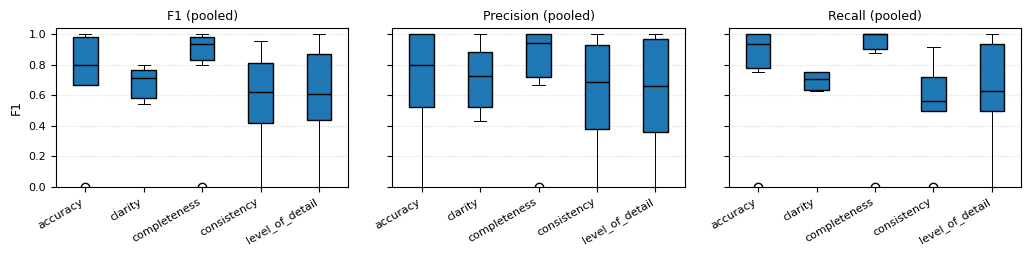

Saved figure: figures/rq2_metrics_by_criterion_pooled.png


In [2]:
N_BOOT = 10000
SEED = 42
CI_METRICS = {"precision": au.precision, "recall": au.recall, "f1": au.f1}

criteria = sorted(merged["Criterion"].unique())

crit_groups: dict[str, tuple[np.ndarray, np.ndarray]] = {}
for crit, g in merged.groupby("Criterion"):
    crit_groups[crit] = (g["gt_label"].to_numpy(), g["llm_label"].to_numpy())

agg_rows = []
f1_by_crit: dict[str, tuple[float, float, float]] = {}
for crit in criteria:
    yt, yp = crit_groups[crit]
    base = au.metrics(yt, yp)
    row = {"Criterion": crit, "n": base["n"], "accuracy": base["accuracy"]}
    for mname, mfn in CI_METRICS.items():
        pt, lo, hi = au.bootstrap_ci(yt, yp, mfn, n_boot=N_BOOT, seed=SEED)
        row[mname] = pt
        row[f"{mname}_lo"] = lo
        row[f"{mname}_hi"] = hi
        if mname == "f1":
            f1_by_crit[crit] = (pt, lo, hi)
    agg_rows.append(row)

per_criterion_aggregated = pd.DataFrame(agg_rows).set_index("Criterion")
print("Items per criterion (pooled):")
print(merged.groupby("Criterion").size().to_string())
display(per_criterion_aggregated.round(4))

metric_panels = [
    ("F1", au.f1),
    ("Precision", au.precision),
    ("Recall", au.recall),
]
fig, axes = plt.subplots(1, 3, figsize=au.FIGSIZE_ROW_3, sharey=True)
for ax, (ylabel, mfn) in zip(axes, metric_panels):
    box_vals = [
        au.values_by_diagram(merged[merged["Criterion"] == crit], mfn)
        for crit in criteria
    ]
    au.slim_boxplot(
        ax, box_vals, criteria,
        title=f"{ylabel} (pooled)",
        ylabel=ylabel if ylabel == "F1" else "",
        panel=True,
        show_ylabel=(ylabel == "F1"),
        label_rotation=30,
    )
if not DRY_RUN:
    au.save_figure(fig, FIG_DIR / "rq2_metrics_by_criterion_pooled.png")
plt.show()
if not DRY_RUN:
    print("Saved figure: figures/rq2_metrics_by_criterion_pooled.png")

## 3. Precision / recall / F1 per (representation, criterion) with bootstrap CIs

In [3]:
N_BOOT = 10000
SEED = 42
CI_METRICS = {"precision": au.precision, "recall": au.recall, "f1": au.f1}

criteria = sorted(merged["Criterion"].unique())
representations = ["image", "text"]

# Store per (rep, criterion) labels and CI results.
cell_groups: dict[tuple[str, str], tuple[np.ndarray, np.ndarray]] = {}
for (rep, crit), g in merged.groupby(["Representation", "Criterion"]):
    cell_groups[(rep, crit)] = (g["gt_label"].to_numpy(), g["llm_label"].to_numpy())

rows = []
ci_by_cell: dict[tuple[str, str], dict[str, tuple[float, float, float]]] = {}
for rep in representations:
    for crit in criteria:
        key = (rep, crit)
        if key not in cell_groups:
            continue
        yt, yp = cell_groups[key]
        base = au.metrics(yt, yp)
        row = {"Representation": rep, "Criterion": crit, "n": base["n"],
               "accuracy": base["accuracy"]}
        ci_by_cell[key] = {}
        for mname, mfn in CI_METRICS.items():
            pt, lo, hi = au.bootstrap_ci(yt, yp, mfn, n_boot=N_BOOT, seed=SEED)
            row[mname] = pt
            row[f"{mname}_lo"] = lo
            row[f"{mname}_hi"] = hi
            ci_by_cell[key][mname] = (pt, lo, hi)
        rows.append(row)

per_criterion = pd.DataFrame(rows)
per_criterion.round(4)

,Representation,Criterion,n,accuracy,precision,precision_lo,precision_hi,recall,recall_lo,recall_hi,f1,f1_lo,f1_hi
0,image,accuracy,24,0.7917,0.7895,0.5882,0.9500,0.9375,0.8000,1.0000,0.8571,0.7097,0.9697
1,image,clarity,48,0.6875,0.7407,0.5652,0.8966,0.7143,0.5385,0.8710,0.7273,0.5714,0.8438
2,image,completeness,36,0.8333,0.7692,0.6000,0.9200,1.0000,1.0000,1.0000,0.8696,0.7500,0.9583
3,image,consistency,36,0.6667,0.7778,0.5625,0.9474,0.6364,0.4286,0.8333,0.7000,0.5143,0.8444
4,image,level_of_detail,36,0.6944,0.6957,0.5000,0.8750,0.8000,0.6111,0.9524,0.7442,0.5789,0.8750
5,text,accuracy,24,0.6667,0.6818,0.4783,0.8696,0.9375,0.8000,1.0000,0.7895,0.6250,0.9091
6,text,clarity,48,0.6250,0.6923,0.5000,0.8636,0.6429,0.4615,0.8148,0.6667,0.5000,0.8000
7,text,completeness,36,0.8056,0.7600,0.5806,0.9167,0.9500,0.8333,1.0000,0.8444,0.7111,0.9434
8,text,consistency,36,0.6389,0.6800,0.5000,0.8571,0.7727,0.5882,0.9412,0.7234,0.5581,0.8519
9,text,level_of_detail,36,0.6944,0.7143,0.5000,0.8947,0.7500,0.5499,0.9375,0.7317,0.5556,0.8679


## 4. Image-vs-text advantage per criterion

For each criterion, bootstrap 95% CI of `F1(image) - F1(text)` and `precision(image) - precision(text)`. Positive means image is better; CI excluding 0 means the gap is robust.

In [4]:
diff_rows = []
for crit in criteria:
    ki, kt = ("image", crit), ("text", crit)
    if ki not in cell_groups or kt not in cell_groups:
        continue
    yt_i, yp_i = cell_groups[ki]
    yt_t, yp_t = cell_groups[kt]
    row = {"Criterion": crit}
    for mname, mfn in (("f1", au.f1), ("precision", au.precision)):
        d = au.bootstrap_diff_ci(yt_i, yp_i, yt_t, yp_t, mfn, n_boot=N_BOOT, seed=SEED)
        row[f"{mname}_img_minus_txt"] = d["diff"]
        row[f"{mname}_lo"] = d["lo"]
        row[f"{mname}_hi"] = d["hi"]
        row[f"{mname}_robust"] = d["excludes_zero"]
    diff_rows.append(row)

diff_by_criterion = pd.DataFrame(diff_rows).set_index("Criterion")
display(diff_by_criterion.round(4))

print("Advantage by criterion (F1):")
for r in diff_by_criterion.itertuples():
    side = "image" if r.f1_img_minus_txt > 0 else "text"
    tag = "ROBUST" if r.f1_robust else "not robust"
    print(f"  {r.Index:>16}: favors {side:5s} by {abs(r.f1_img_minus_txt):.3f} F1 ({tag})")

,f1_img_minus_txt,f1_lo,f1_hi,f1_robust,precision_img_minus_txt,precision_lo,precision_hi,precision_robust
Criterion,,,,,,,,
accuracy,0.0677,-0.1299,0.2689,False,0.1077,-0.1643,0.3759,False
clarity,0.0606,-0.1433,0.2632,False,0.0484,-0.1983,0.2929,False
completeness,0.0251,-0.1296,0.1869,False,0.0092,-0.2210,0.2428,False
consistency,-0.0234,-0.2500,0.2013,False,0.0978,-0.1780,0.3611,False
level_of_detail,0.0125,-0.2023,0.2370,False,-0.0186,-0.2857,0.2593,False


Advantage by criterion (F1):
          accuracy: favors image by 0.068 F1 (not robust)
           clarity: favors image by 0.061 F1 (not robust)
      completeness: favors image by 0.025 F1 (not robust)
       consistency: favors text  by 0.023 F1 (not robust)
   level_of_detail: favors image by 0.012 F1 (not robust)


## 5. Charts (image vs text)

Grouped empirical boxplots: F1 per diagram within each (representation, criterion) cell.

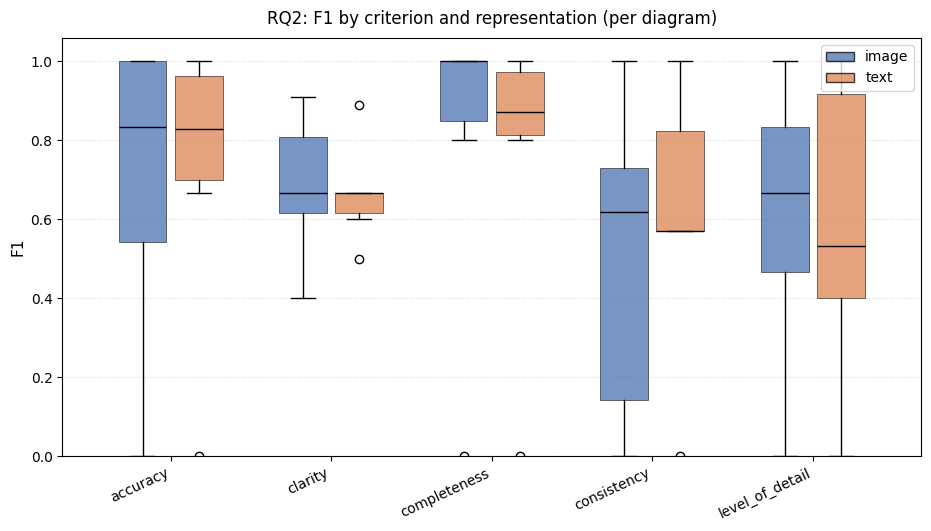

Saved figure: figures/rq2_f1_by_criterion.png


In [5]:
box_data = {rep: [] for rep in representations}
for rep in representations:
    for crit in criteria:
        sub = merged[(merged["Representation"] == rep) & (merged["Criterion"] == crit)]
        box_data[rep].append(au.values_by_diagram(sub, au.f1) if len(sub) else [])

fig, ax = plt.subplots(figsize=au.FIGSIZE_WIDE)
au.slim_grouped_boxplot(
    ax,
    box_data=box_data,
    group_labels=criteria,
    series_names=representations,
    title="RQ2: F1 by criterion and representation (per diagram)"
    + ("  [DRY-RUN]" if DRY_RUN else ""),
    ylabel="F1",
)
if not DRY_RUN:
    au.save_figure(fig, FIG_DIR / "rq2_f1_by_criterion.png")
plt.show()
if not DRY_RUN:
    print("Saved figure: figures/rq2_f1_by_criterion.png")

## 6. Ordinal agreement by criterion

Quadratic weighted Cohen's kappa computed per diagram, grouped by criterion (empirical boxplot; bootstrap CIs in RQ1 text/CSV).

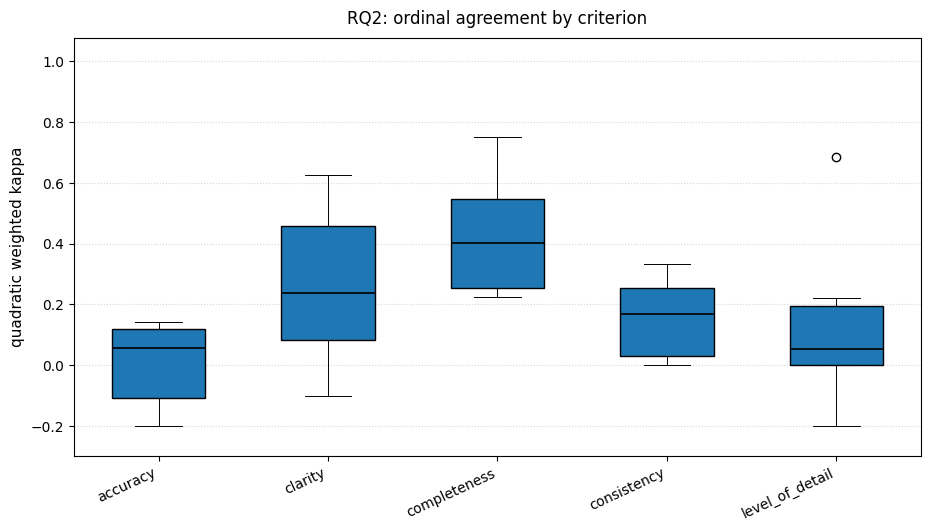

Saved figure: figures/rq2_kappa_by_criterion.png


In [6]:
EVAL_ORDINAL = CSV_DIR / "llm-evaluations" / "evaluations_ordinal.csv"
evals_ord = pd.read_csv(EVAL_ORDINAL)
gt_ord_full = pd.read_csv(GT_ORDINAL)
ord_merged = evals_ord.merge(
    gt_ord_full[["Diagram_ID", "Criterion", "Guideline", "gt_score_mean"]],
    on=["Diagram_ID", "Criterion", "Guideline"],
    how="inner",
)
GRID = au.ordinal_scale(1.0, 4.0, 0.5)

kappa_by_crit = [
    au.kappa_values_by_diagram(ord_merged[ord_merged["Criterion"] == crit], labels=GRID)
    for crit in criteria
]

fig, ax = plt.subplots(figsize=au.FIGSIZE_WIDE)
au.slim_boxplot(
    ax,
    kappa_by_crit,
    criteria,
    title="RQ2: ordinal agreement by criterion",
    ylabel="quadratic weighted kappa",
    ylim=(-0.3, 1.0),
)
if not DRY_RUN:
    au.save_figure(fig, FIG_DIR / "rq2_kappa_by_criterion.png")
plt.show()
if not DRY_RUN:
    print("Saved figure: figures/rq2_kappa_by_criterion.png")

## 7. Export

In [7]:
if DRY_RUN:
    print("DRY-RUN: tables NOT saved. Fill the boundary decisions and re-run for real output.")
else:
    per_criterion_aggregated.reset_index().to_csv(OUT_TABLE_AGGREGATED, index=False)
    per_criterion.to_csv(OUT_TABLE, index=False)
    diff_by_criterion.to_csv(NOTEBOOK_DIR / "rq2_image_vs_text_by_criterion.csv")
    print(f"Saved: {OUT_TABLE_AGGREGATED.name}")
    print(f"Saved: {OUT_TABLE.name}")
    print("Saved: rq2_image_vs_text_by_criterion.csv")
    print("Saved figures in:", FIG_DIR)

Saved: rq2_f1_per_criterion_aggregated.csv
Saved: rq2_per_criterion.csv
Saved: rq2_image_vs_text_by_criterion.csv
Saved figures in: C:\Users\João Luiz\Desktop\Trabalhos facul\POC\llm-architecure-assesment\research-files\analysis-csv\rq-analysis\figures
